In [ ]:
# Guided Activities

In [ ]:
# Activity 01

In [1]:

import random

# Eight directions: up, down, left, right and the four diagonals
DIRS = [
    (-1, 0), (1, 0), (0, -1), (0, 1),
    (-1, -1), (-1, 1), (1, -1), (1, 1)
]


class Courtyard:
    """The environment and its agents: students on a wrapped grid."""

    def __init__(self, n=12, size=5, p=0.3, seed=0):
        self.rng = random.Random(seed)
        self.n, self.size, self.p, self.tick = n, size, p, 0

        # Attribute 1: where each student stands
        self.pos = [
            (self.rng.randrange(size), self.rng.randrange(size))
            for _ in range(n)
        ]

        # Attribute 2: does each student know the rumour?
        self.knows = [False] * n
        self.knows[0] = True  # Student 0 starts the rumour

    def count(self):
        return sum(self.knows)

    def render(self):
        """K = knows the rumour, s = does not, . = empty."""
        rows = [["."] * self.size for _ in range(self.size)]

        for i, (r, c) in enumerate(self.pos):
            if self.knows[i]:
                rows[r][c] = "K"
            elif rows[r][c] == ".":
                rows[r][c] = "s"

        return "\n".join("".join(row) for row in rows)


courtyard = Courtyard(n=12, size=5, p=0.3, seed=1)

print(courtyard.render())
print("Students who know the rumour:", courtyard.count())


..ss.
....K
ss...
.s.ss
s....
Students who know the rumour: 1


In [ ]:
# Activity 02

In [3]:

    def move_all(self):
        for i in range(self.n):
            dr, dc = self.rng.choice(DIRS)
            r, c = self.pos[i]
            self.pos[i] = (
                (r + dr) % self.size,
                (c + dc) % self.size
            )  # Wrap around the grid

    def next_to_knower(self, cell, know_cells):
        r, c = cell
        return any(
            ((r + a) % self.size, (c + b) % self.size) in know_cells
            for a in (-1, 0, 1)
            for b in (-1, 0, 1)
        )

    def spread(self):
        know_cells = {
            self.pos[i]
            for i in range(self.n)
            if self.knows[i]
        }

        newly = [
            i for i in range(self.n)
            if not self.knows[i]
            and self.next_to_knower(self.pos[i], know_cells)
            and self.rng.random() < self.p
        ]

        for i in newly:
            self.knows[i] = True

    def step(self):  # One tick
        self.move_all()
        self.spread()
        self.tick += 1


In [ ]:
# Activity 03

In [14]:

import random

DIRS = [
    (-1, 0), (1, 0), (0, -1), (0, 1),
    (-1, -1), (-1, 1), (1, -1), (1, 1)
]


class Courtyard:
    """Students on a wrapped grid."""

    def __init__(self, n=100, size=30, p=0.3, seed=0):
        self.rng = random.Random(seed)
        self.n = n
        self.size = size
        self.p = p
        self.tick = 0

        self.pos = [
            (self.rng.randrange(size), self.rng.randrange(size))
            for _ in range(n)
        ]

        self.knows = [False] * n
        self.knows[0] = True

    def count(self):
        return sum(self.knows)

    def render(self):
        rows = [["."] * self.size for _ in range(self.size)]

        for i, (r, c) in enumerate(self.pos):
            if self.knows[i]:
                rows[r][c] = "K"
            elif rows[r][c] == ".":
                rows[r][c] = "s"

        return "\n".join("".join(row) for row in rows)

    def move_all(self):
        for i in range(self.n):
            dr, dc = self.rng.choice(DIRS)
            r, c = self.pos[i]
            self.pos[i] = (
                (r + dr) % self.size,
                (c + dc) % self.size
            )

    def next_to_knower(self, cell, know_cells):
        r, c = cell
        return any(
            ((r + a) % self.size, (c + b) % self.size) in know_cells
            for a in (-1, 0, 1)
            for b in (-1, 0, 1)
            if a != 0 or b != 0
        )

    def spread(self):
        know_cells = {
            self.pos[i]
            for i in range(self.n)
            if self.knows[i]
        }

        newly = [
            i for i in range(self.n)
            if not self.knows[i]
            and self.next_to_knower(self.pos[i], know_cells)
            and self.rng.random() < self.p
        ]

        for i in newly:
            self.knows[i] = True

    def step(self):
        self.move_all()
        self.spread()
        self.tick += 1


def run_rumour(model, max_ticks=600, every=10):
    print("tick  knowers")
    print(f"{model.tick:4d}  {model.count():3d}")

    while model.count() < model.n and model.tick < max_ticks:
        model.step()

        if model.tick % every == 0:
            print(f"{model.tick:4d}  {model.count():3d}")

    if model.count() == model.n:
        print(f"Everyone knows after {model.tick} ticks")
    else:
        print(
            f"Stopped at tick {model.tick} "
            f"with {model.count()} knowers"
        )


run_rumour(Courtyard(n=100, size=30, p=0.3, seed=1))


tick  knowers
   0    1
  10    4
  20    8
  30   18
  40   34
  50   45
  60   68
  70   87
  80   94
  90   99
Everyone knows after 96 ticks


In [ ]:
# Independent Tasks

In [ ]:
# Task 01

In [15]:

import statistics

def ticks_until(model, fraction, max_ticks=600):
    target = fraction * model.n

    while model.count() < target and model.tick < max_ticks:
        model.step()

    return model.tick


def average_ticks(p, fraction, seeds=range(30), **kwargs):
    return statistics.mean(
        ticks_until(Courtyard(p=p, seed=s, **kwargs), fraction)
        for s in seeds
    )


print(
    "Half know after",
    round(average_ticks(0.3, 0.5), 1),
    "ticks on average"
)

print(
    "90 percent know after",
    round(average_ticks(0.3, 0.9), 1),
    "ticks on average"
)

runs = [
    ticks_until(Courtyard(p=0.3, seed=s), 0.9)
    for s in range(30)
]

print(
    "Single runs to 90 percent: fastest",
    min(runs),
    ", slowest",
    max(runs)
)


# Additional Experiment: Comparing Different Probabilities

for p in [0.1, 0.3, 0.5]:
    avg = average_ticks(p, 0.9)
    print(
        f"Probability {p}: 90% know after "
        f"{avg:.1f} ticks on average"
    )


Half know after 47.1 ticks on average
90 percent know after 69.3 ticks on average
Single runs to 90 percent: fastest 53 , slowest 85
Probability 0.1: 90% know after 127.7 ticks on average
Probability 0.3: 90% know after 69.3 ticks on average
Probability 0.5: 90% know after 54.9 ticks on average


In [ ]:
# Task 02

In [16]:

import random
import statistics

# Eight directions
DIRS = [
    (-1, 0), (1, 0), (0, -1), (0, 1),
    (-1, -1), (-1, 1), (1, -1), (1, 1)
]


class Courtyard:
    """Students on a wrapped grid."""

    def __init__(self, n=100, size=30, p=0.3, seed=0):
        self.rng = random.Random(seed)
        self.n = n
        self.size = size
        self.p = p
        self.tick = 0

        self.pos = [
            (self.rng.randrange(size), self.rng.randrange(size))
            for _ in range(n)
        ]

        self.knows = [False] * n
        self.knows[0] = True

    def count(self):
        return sum(self.knows)

    def move_all(self):
        for i in range(self.n):
            dr, dc = self.rng.choice(DIRS)
            r, c = self.pos[i]
            self.pos[i] = (
                (r + dr) % self.size,
                (c + dc) % self.size
            )

    def next_to_knower(self, cell, know_cells):
        r, c = cell
        return any(
            ((r + a) % self.size, (c + b) % self.size) in know_cells
            for a in (-1, 0, 1)
            for b in (-1, 0, 1)
            if a != 0 or b != 0
        )

    def spread(self):
        know_cells = {
            self.pos[i]
            for i in range(self.n)
            if self.knows[i]
        }

        newly = [
            i for i in range(self.n)
            if not self.knows[i]
            and self.next_to_knower(self.pos[i], know_cells)
            and self.rng.random() < self.p
        ]

        for i in newly:
            self.knows[i] = True

    def step(self):
        self.move_all()
        self.spread()
        self.tick += 1


def ticks_until(model, fraction, max_ticks=600):
    target = fraction * model.n

    while model.count() < target and model.tick < max_ticks:
        model.step()

    return model.tick


def average_ticks(p, fraction, seeds=range(30), **kwargs):
    return statistics.mean(
        ticks_until(Courtyard(p=p, seed=s, **kwargs), fraction)
        for s in seeds
    )


# Lab Task 2: Change only the spreading probability

for p in [0.1, 0.3, 0.6, 1.0]:
    half = average_ticks(p, 0.5)
    ninety = average_ticks(p, 0.9)

    print(f"p = {p}: half {half:.1f}, 90% {ninety:.1f}")


p = 0.1: half 86.9, 90% 127.7
p = 0.3: half 47.1, 90% 69.3
p = 0.6: half 35.3, 90% 50.0
p = 1.0: half 25.8, 90% 38.9


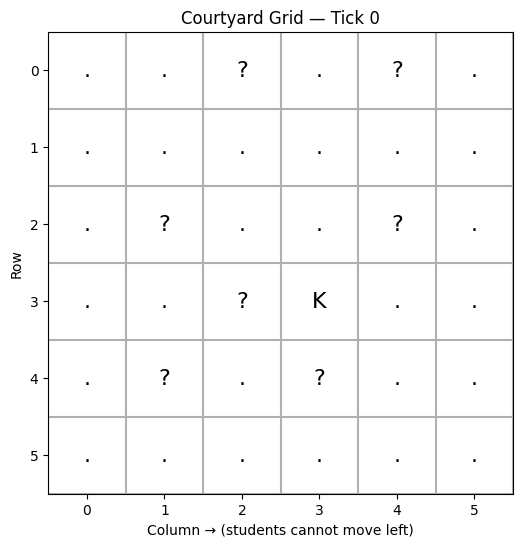

In [45]:
import matplotlib.pyplot as plt
import numpy as np

def show_grid(model):
    grid = np.full((model.size, model.size), ".")

    for i, (r, c) in enumerate(model.pos):
        grid[r, c] = "K" if model.knows[i] else "?"

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.set_xlim(-0.5, model.size - 0.5)
    ax.set_ylim(model.size - 0.5, -0.5)
    ax.set_xticks(range(model.size))
    ax.set_yticks(range(model.size))
    ax.set_xticks(np.arange(-0.5, model.size, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, model.size, 1), minor=True)
    ax.grid(which="minor", linewidth=1.5)
    ax.tick_params(which="minor", bottom=False, left=False)

    for r in range(model.size):
        for c in range(model.size):
            ax.text(c, r, grid[r, c], ha="center", va="center", fontsize=16)

    ax.set_title(f"Courtyard Grid — Tick {model.tick}")
    ax.set_xlabel("Column → (students cannot move left)")
    ax.set_ylabel("Row")
    plt.show()


# Create a model and display its starting grid
model = Courtyard(n=10, size=6, p=0.5, forget_p=0.05, seed=0)
show_grid(model)

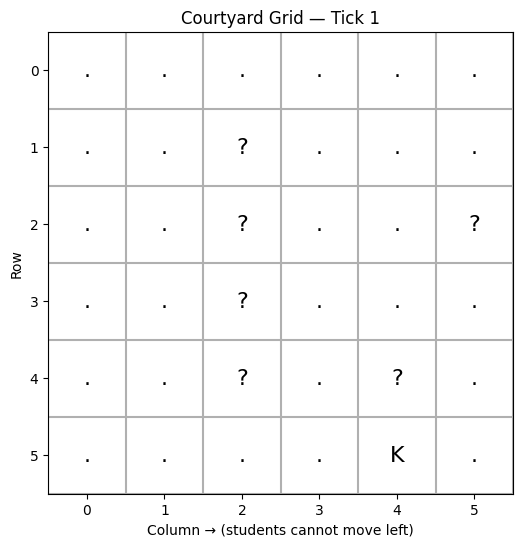

In [46]:
model.step()
show_grid(model)

In [ ]:
# Task 03

In [17]:

import random
import statistics

DIRS = [
    (-1, 0), (1, 0), (0, -1), (0, 1),
    (-1, -1), (-1, 1), (1, -1), (1, 1)
]


class Courtyard:
    def __init__(self, n=100, size=30, p=0.3, seed=0):
        self.rng = random.Random(seed)
        self.n = n
        self.size = size
        self.p = p
        self.tick = 0

        self.pos = [
            (self.rng.randrange(size), self.rng.randrange(size))
            for _ in range(n)
        ]

        self.knows = [False] * n
        self.knows[0] = True

    def count(self):
        return sum(self.knows)

    def move_all(self):
        for i in range(self.n):
            dr, dc = self.rng.choice(DIRS)
            r, c = self.pos[i]
            self.pos[i] = (
                (r + dr) % self.size,
                (c + dc) % self.size
            )

    def next_to_knower(self, cell, know_cells):
        r, c = cell
        return any(
            ((r + a) % self.size, (c + b) % self.size) in know_cells
            for a in (-1, 0, 1)
            for b in (-1, 0, 1)
            if a != 0 or b != 0
        )

    def spread(self):
        know_cells = {
            self.pos[i] for i in range(self.n) if self.knows[i]
        }

        newly = [
            i for i in range(self.n)
            if not self.knows[i]
            and self.next_to_knower(self.pos[i], know_cells)
            and self.rng.random() < self.p
        ]

        for i in newly:
            self.knows[i] = True

    def step(self):
        self.move_all()
        self.spread()
        self.tick += 1


# Lab Task 3: Students who stay home
class CourtyardStayHome(Courtyard):
    def __init__(self, stay_home=0.0, **kwargs):
        super().__init__(**kwargs)
        k = round(stay_home * self.n)
        self.frozen = set(range(self.n - k, self.n))

    def move_all(self):
        for i in range(self.n):
            if i not in self.frozen:
                dr, dc = self.rng.choice(DIRS)
                r, c = self.pos[i]
                self.pos[i] = (
                    (r + dr) % self.size,
                    (c + dc) % self.size
                )

    # Additional rule:
    # Students staying home need at least two distinct
    # neighbouring cells containing knowers to learn.
    def spread(self):
        know_cells = {
            self.pos[i] for i in range(self.n) if self.knows[i]
        }

        newly = []

        for i in range(self.n):
            if self.knows[i]:
                continue

            cell = self.pos[i]
            r, c = cell

            neighbours = {
                ((r + a) % self.size, (c + b) % self.size)
                for a in (-1, 0, 1)
                for b in (-1, 0, 1)
                if a != 0 or b != 0
            }

            nearby_knower_cells = neighbours & know_cells

            if i in self.frozen:
                eligible = len(nearby_knower_cells) >= 2
            else:
                eligible = len(nearby_knower_cells) >= 1

            if eligible and self.rng.random() < self.p:
                newly.append(i)

        for i in newly:
            self.knows[i] = True


def ticks_until(model, fraction, max_ticks=600):
    target = fraction * model.n

    while model.count() < target and model.tick < max_ticks:
        model.step()

    return model.tick


# Compare different fractions of students staying home
for stay_home in [0.0, 0.3, 0.6]:
    half = statistics.mean(
        ticks_until(
            CourtyardStayHome(stay_home=stay_home, seed=s), 0.5
        )
        for s in range(30)
    )

    ninety = statistics.mean(
        ticks_until(
            CourtyardStayHome(stay_home=stay_home, seed=s), 0.9
        )
        for s in range(30)
    )

    everyone = 0

    for s in range(30):
        m = CourtyardStayHome(stay_home=stay_home, seed=s)
        ticks_until(m, 1.0)
        everyone += (m.count() == m.n)

    print(
        f"stay home {stay_home}: half {half:.1f}, "
        f"90% {ninety:.1f}, "
        f"everyone knows in {everyone} of 30 runs"
    )


stay home 0.0: half 47.1, 90% 69.3, everyone knows in 30 of 30 runs
stay home 0.3: half 62.7, 90% 113.5, everyone knows in 30 of 30 runs
stay home 0.6: half 112.2, 90% 269.5, everyone knows in 15 of 30 runs


In [ ]:
# Task 04

In [18]:

import random
import statistics


class Town:
    def __init__(self, size=40, empty=0.10, threshold=0.40, seed=0):
        self.rng = random.Random(seed)
        self.size = size
        self.threshold = threshold

        cells = size * size
        n_empty = round(empty * cells)
        n_each = (cells - n_empty) // 2

        values = (
            [1] * n_each
            + [2] * (cells - n_empty - n_each)
            + [0] * n_empty
        )

        self.rng.shuffle(values)
        self.grid = [
            values[r * size:(r + 1) * size]
            for r in range(size)
        ]

        # Additional rule: moved residents are more tolerant
        # during the next round.
        self.temporary_tolerance = set()

    def neighbours(self, r, c):
        s = self.size
        return [
            self.grid[(r + a) % s][(c + b) % s]
            for a in (-1, 0, 1)
            for b in (-1, 0, 1)
            if (a, b) != (0, 0)
        ]

    def agents(self):
        return [
            (r, c)
            for r in range(self.size)
            for c in range(self.size)
            if self.grid[r][c] != 0
        ]

    def empties(self):
        return [
            (r, c)
            for r in range(self.size)
            for c in range(self.size)
            if self.grid[r][c] == 0
        ]

    def like_share(self, r, c):
        group = self.grid[r][c]
        occupied = [
            value for value in self.neighbours(r, c)
            if value != 0
        ]

        if not occupied:
            return 1.0

        return sum(value == group for value in occupied) / len(occupied)

    def is_content(self, r, c):
        threshold = (
            0.20
            if (r, c) in self.temporary_tolerance
            else self.threshold
        )
        return self.like_share(r, c) >= threshold

    def average_like_share(self):
        a = self.agents()
        return sum(self.like_share(r, c) for r, c in a) / len(a)

    def discontent(self):
        return [
            (r, c) for r, c in self.agents()
            if not self.is_content(r, c)
        ]

    def play_round(self):
        # Residents who moved last round get temporary tolerance
        self.temporary_tolerance.clear()

        movers = self.discontent()
        self.rng.shuffle(movers)
        empties = self.empties()

        moved_residents = []

        for r, c in movers:
            if not empties:
                break

            j = self.rng.randrange(len(empties))
            er, ec = empties[j]

            group = self.grid[r][c]
            self.grid[er][ec] = group
            self.grid[r][c] = 0

            empties[j] = (r, c)
            moved_residents.append((er, ec))

        # These residents have temporary tolerance for the next round.
        self.temporary_tolerance = set(moved_residents)

        return len(moved_residents)


# Run and record
town = Town(threshold=0.4, seed=3)

print(
    "Start: like share",
    round(town.average_like_share(), 2),
    ", discontent:",
    len(town.discontent())
)

rounds = 0

while True:
    moved = town.play_round()
    rounds += 1

    if rounds in (1, 2, 5, 10, 15) or moved == 0:
        print(
            f"Round {rounds}: moved {moved}, "
            f"like share {town.average_like_share():.2f}"
        )

    if moved == 0 or rounds >= 100:
        break


# Compare different thresholds
for threshold in [0.2, 0.4, 0.6]:
    rounds_used = []
    shares = []

    for s in range(10):
        town = Town(threshold=threshold, seed=s)
        r = 0

        while r < 100:
            moved = town.play_round()
            r += 1

            if moved == 0:
                break

        rounds_used.append(r)
        shares.append(town.average_like_share())

    print(
        f"threshold {threshold}: rounds "
        f"{statistics.mean(rounds_used):.1f}, "
        f"like share {statistics.mean(shares):.2f}"
    )


Start: like share 0.49 , discontent: 459
Round 1: moved 459, like share 0.62
Round 2: moved 245, like share 0.70
Round 5: moved 60, like share 0.81
Round 10: moved 13, like share 0.84
Round 15: moved 3, like share 0.85
Round 22: moved 0, like share 0.85
threshold 0.2: rounds 7.2, like share 0.58
threshold 0.4: rounds 17.6, like share 0.82
threshold 0.6: rounds 92.2, like share 0.97


In [ ]:
# Task 05

In [19]:

import random
import statistics

SPOTS = ["crate", "door", "shelf", "barrel", "curtain"]
HIDE_PROB = [0.10, 0.45, 0.05, 0.30, 0.10]


class HidingPlayer:
    def __init__(self, seed):
        self.rng = random.Random(seed)

    def hide(self):
        return self.rng.choices(
            range(len(SPOTS)), weights=HIDE_PROB
        )[0]


def critic(spot, hidden):
    return 1 if spot == hidden else 0


class LearningGuard:
    def __init__(self, epsilon, seed):
        self.epsilon = epsilon
        self.rng = random.Random(seed)
        self.checked = [0.0] * len(SPOTS)
        self.found = [0.0] * len(SPOTS)

    def estimate(self, i):
        if self.checked[i] == 0:
            return 0.0
        return self.found[i] / self.checked[i]

    def choose(self):
        if self.rng.random() < self.epsilon:
            return self.rng.randrange(len(SPOTS))

        estimates = [self.estimate(i) for i in range(len(SPOTS))]
        best = max(estimates)
        choices = [
            i for i, value in enumerate(estimates)
            if value == best
        ]
        return self.rng.choice(choices)

    def learn(self, spot, reward):
        # Additional rule: fade old memories by 1% each round
        self.checked = [value * 0.99 for value in self.checked]
        self.found = [value * 0.99 for value in self.found]

        self.checked[spot] += 1
        self.found[spot] += reward


def play(epsilon, rounds=500, seed=0):
    guard = LearningGuard(epsilon, seed)
    player = HidingPlayer(1000 + seed)
    wins = 0

    for _ in range(rounds):
        spot = guard.choose()
        reward = critic(spot, player.hide())
        guard.learn(spot, reward)
        wins += reward

    return wins / rounds, guard


# Compare different exploration rates
for epsilon in [1.0, 0.0, 0.05, 0.1, 0.3]:
    rates = [
        play(epsilon, 500, seed)[0]
        for seed in range(100)
    ]
    print(
        f"epsilon {epsilon}: "
        f"success rate {statistics.mean(rates):.3f}"
    )


# Inspect two individual games
for epsilon in [0.1, 0.0]:
    rate, guard = play(epsilon, 500, 0)
    print(
        "epsilon", epsilon,
        "seed 0: success", round(rate, 3),
        "checks", [round(x, 1) for x in guard.checked]
    )


epsilon 1.0: success rate 0.201
epsilon 0.0: success rate 0.327
epsilon 0.05: success rate 0.384
epsilon 0.1: success rate 0.397
epsilon 0.3: success rate 0.361
epsilon 0.1 seed 0: success 0.39 checks [2.7, 92.6, 1.8, 1.7, 0.5]
epsilon 0.0 seed 0: success 0.318 checks [0.0, 0.0, 0.0, 99.3, 0.0]
